| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

# Tugas Image Enhancement pada Citra Satelit

* **Citra Satelit:** Foto permukaan bumi dari luar angkasa menggunakan sensor berspektrum luas (seperti RGB) untuk keperluan analisis lingkungan dan lahan.
* **Landsat:** Program satelit observasi bumi (NASA & USGS) yang menghasilkan citra multispektral mentah (*raw data*) untuk keperluan penelitian ilmiah.
* **Google Earth Image:** Mosaik gabungan dari berbagai sumber citra satelit dan foto udara yang sudah diproses (koreksi warna dan distorsi) agar terlihat mulus bagi pengguna umum.

Citra satelit mentah seringkali kurang optimal (berkabut, kontras rendah, atau ada *noise*) karena gangguan atmosfer. **Image Enhancement** dilakukan untuk memperbaiki kualitas visual citra dan menonjolkan fitur-fitur penting (seperti batas jalan/sungai) tanpa menambah informasi baru.

### 1. Membaca Citra Input
Membaca citra menggunakan OpenCV yang secara default menggunakan format warna BGR. Menggunakan Matplotlib untuk visualisasi, citra dikonversi dulu ke dalam  RGB.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

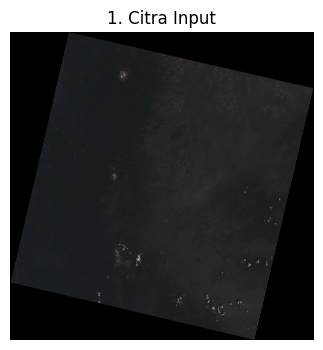

In [3]:
img_rgb = cv2.imread('citra_input.png')  # Pastikan nama file sesuai
img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.title("1. Citra Input")
plt.axis('off')
plt.show()

### 2. Peningkatan Kecerahan dan Kontras Global
Langkah *pre-processing* pertama adalah transformasi linier untuk meningkatkan visibilitas citra yang sangat gelap. Parameter `alpha` (2.5) digunakan sebagai pengali untuk meregangkan kontras, sedangkan `beta` (40) ditambahkan untuk menaikkan level kecerahan dasar piksel.

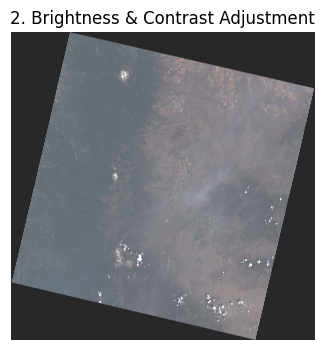

In [4]:
alpha_val = 2.5
beta_val = 40
img_bright = cv2.convertScaleAbs(img_rgb, alpha=alpha_val, beta=beta_val)

plt.figure(figsize=(6, 4))
plt.imshow(img_bright)
plt.title("2. Brightness & Contrast Adjustment")
plt.axis('off')
plt.show()

### 3. Ekualisasi Histogram 
Untuk meratakan distribusi intensitas cahaya yang mungkin masih menumpuk di nilai tertentu, dilakukan *Histogram Equalization*. Karena ini citra berwarna, ekualisasi dilakukan secara terpisah pada masing-masing channel (R, G, B) lalu digabungkan kembali.

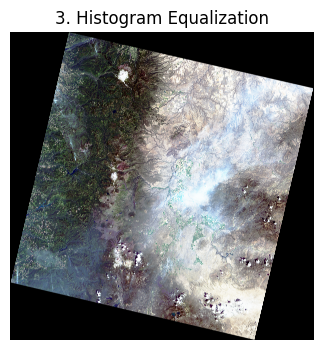

In [5]:
ch_r, ch_g, ch_b = cv2.split(img_bright)
hist_eq = cv2.merge((cv2.equalizeHist(ch_r), 
                     cv2.equalizeHist(ch_g), 
                     cv2.equalizeHist(ch_b)))

plt.figure(figsize=(6, 4))
plt.imshow(hist_eq)
plt.title("3. Histogram Equalization")
plt.axis('off')
plt.show()

### 4. Peningkatan Kontras Lokal Adaptif (CLAHE)
Ekualisasi histogram global terkadang menyebabkan distorsi pada beberapa area. Sebagai perbaikan, diterapkan CLAHE (*Contrast Limited Adaptive Histogram Equalization*). Agar warna tidak berubah, citra dikonversi ke ruang warna LAB, di mana CLAHE hanya beroperasi pada channel L (*Lightness*).

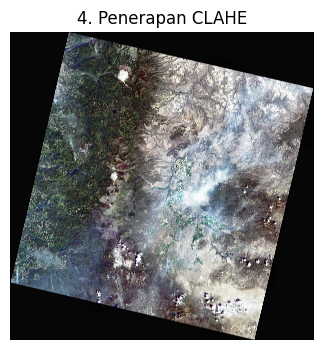

In [6]:
lab_img = cv2.cvtColor(hist_eq, cv2.COLOR_RGB2LAB)
l_channel, a_channel, b_channel = cv2.split(lab_img)

clahe_processor = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
l_clahe = clahe_processor.apply(l_channel)

clahe_preview = cv2.cvtColor(cv2.merge((l_clahe, a_channel, b_channel)), cv2.COLOR_LAB2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(clahe_preview)
plt.title("4. Penerapan CLAHE")
plt.axis('off')
plt.show()

### 5. High-Frequency Emphasis 
Untuk menajamkan citra, kita meninggalkan metode konvolusi spasial dan beralih ke **Domain Frekuensi** untuk hasil yang lebih presisi. 

Fungsi di bawah mengimplementasikan tahapan:
1. **Transformasi Fourier (FFT)** dan *Shift* ke tengah.
2. Pembuatan **Gaussian High Pass Filter (GHPF)** untuk menghindari *ringing effect*.
3. Modifikasi GHPF menjadi kurva **High-Frequency Emphasis (HFE)** menggunakan parameter `a` (offset) untuk mempertahankan informasi warna/cahaya, dan `b` (multiplier) untuk memperkuat detail/tepi.
4. **Inverse FFT** untuk mengembalikan citra ke bentuk spasial.

In [7]:
def high_frequency_emphasis_filter(image, D0, a=0.8, b=1.5):
    # 1. FFT & Shift
    dft = np.fft.fft2(image)
    dft_shift = np.fft.fftshift(dft)
    
    # 2. Membuat GHPF
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    u = np.arange(rows)
    v = np.arange(cols)
    U, V = np.meshgrid(v, u)
    D = np.sqrt((U - ccol)**2 + (V - crow)**2)
    
    ghpf_mask = 1 - np.exp(-(D**2) / (2 * (D0**2)))
    
    # 3. HIGH-FREQUENCY EMPHASIS (HFE)
    hfe_mask = a + (b * ghpf_mask)
    
    # 4. Diagram Pemrosesan
    filtered_dft = dft_shift * hfe_mask
    
    # 5. Inverse Shift & Inverse FFT
    f_ishift = np.fft.ifftshift(filtered_dft)
    img_back = np.fft.ifft2(f_ishift)
    img_back = np.abs(img_back) 
    
    # Normalisasi tipe data
    img_back = np.clip(img_back, 0, 255).astype(np.uint8)
    
    return img_back, hfe_mask

### 6. Menerapkan Penajaman Frekuensi
Fungsi HFE diaplikasikan secara khusus pada *channel Lightness* (L) yang sebelumnya sudah diproses dengan CLAHE. Parameter *cutoff* ($D_0$) diatur pada 40. Hasil penajaman ini kemudian digabungkan kembali dengan channel A dan B yang asli.

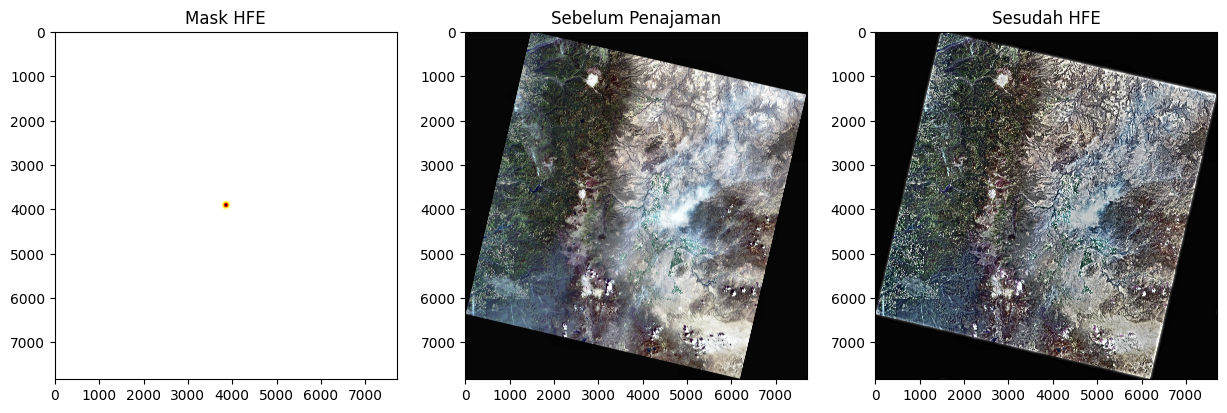

In [8]:
# Menerapkan HFE pada Channel L
l_sharpened_freq, hfe_mask = high_frequency_emphasis_filter(l_clahe, D0=40, a=0.8, b=1.5)

# Menggabungkan kembali dengan channel warna
freq_result_lab = cv2.merge((l_sharpened_freq, a_channel, b_channel))
freq_result_rgb = cv2.cvtColor(freq_result_lab, cv2.COLOR_LAB2RGB)

# Visualisasi Mask dan Hasil Penajaman
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(hfe_mask, cmap='hot'), plt.title('Mask HFE')
plt.subplot(132), plt.imshow(clahe_preview), plt.title('Sebelum Penajaman')
plt.subplot(133), plt.imshow(freq_result_rgb), plt.title('Sesudah HFE')
plt.show()

### 7. Denoising
Meskipun GHPF meminimalisir *ringing*, amplifikasi frekuensi tinggi tetap berisiko mengangkat *noise* sensor. **Non-Local Means Denoising** (h=7) diterapkan untuk menghaluskan tekstur tanpa merusak ketajaman tepi yang telah dibentuk.

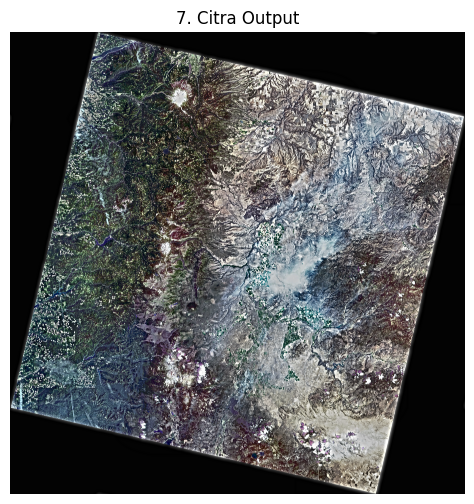

In [ ]:
# Parameter Denoising diatur tidak terlalu tinggi agar detail HFE tidak hilang
final_denoised = cv2.fastNlMeansDenoisingColored(freq_result_rgb, None, 7, 7, 7, 21)

plt.figure(figsize=(8, 6))
plt.imshow(final_denoised)
plt.title("7. Citra Output")
plt.axis('off')
plt.show()

### 8. Menyimpan output

In [12]:
plt.imsave('output_enhancement.png', final_denoised)

print("Gambar berhasil disimpan!")

Gambar berhasil disimpan!


### Kesimpulan

* **Masalah Utama:** Citra satelit mentah (seperti Landsat) sering memiliki kontras rendah dan detail kabur akibat gangguan atmosfer.
* **Tujuan:** Meningkatkan kualitas visual dan menonjolkan fitur penting (jalan/sungai) tanpa mengubah data asli.
* **Metode:**
    * **CLAHE:** Meratakan kontras pencahayaan lokal (memperbaiki latar belakang).
    * **HFE (High-Frequency Emphasis):** Menajamkan detail tepi dan batas wilayah.
* **Hasil:** Citra menjadi lebih tajam dan jelas